# 09 — A drift-aware production posterior [α, β, δT] (System I, N3)

**Why.** The production posterior (notebook 36) knows nothing about a temperature-sensor offset. Under Sc7 (+2 K on the T sensor) it is confidently wrong:
β̂ biased by −0.395, 90% coverage 0.002 (notebook 11), and the residual detector z_T flags it (notebook 11b). The question here is whether making the offset a parameter of the posterior removes
the failure, and what it costs in the well-specified scenarios. The result decides whether Sc7 enters the main text as a remedied failure.

**Model (fixed before running; runbook §2f row f).** θ = [α, β, δT]; prior α, β ~ U(0.4, 1.2) (production), δT ~ U(−3, 3) K. Simulator = the production model of notebook 36 (protocol P2, N3 sensors, true inlet from the notebook-35
distribution, *measured* Ti, Tci with ε = 0.1 K) with δT added to the temperature channel after the sensor layer, as in the Sc7 generation; S1m features from the drifted window. 20,000 simulations × 5 seeds, ensemble (as notebook 36).
δCi of the old notebook 09 is dropped (Ci is the unmeasured ±1% nuisance of the simulator). **Evaluation:** an SBC set of 1,000 prior draws; D1 and L1 (1,000 windows per scenario, seed base 3 800 000, as notebook 11), with the three
numbers per scenario for β and the δT bias, sd and coverage; the 2-D production numbers from notebook 11; a descriptive extension at (α, β) = (0.85, 0.85) with δT ∈ {0, 0.25, 0.5, 1, 2} (200 windows each).

**Pre-set decision rule.** All of: (i) ensemble SBC, interior subset (5% margin per dimension): KS p ≥ 0.01 for α, β and δT, TARP KS p ≥ 0.01; (ii) L1 Sc7: β coverage ≥ 0.80 and |β bias| ≤ 0.05;
(iii) L1 Sc7: δT coverage ≥ 0.80 and |δT bias| ≤ 0.30 K; (iv) L1 Sc1–Sc5: β coverage ≥ 0.80 each and macro-F1 ≥ 0.877 (production 0.907 minus a price of 0.03) → **FIXED** (Sc7 enters the main text with the remedy); otherwise
**NOT FIXED** (Sc7 stays a documented limitation, the drift-aware result goes to the SI). A failed (i) stops the notebook's decision step and is reported, not retuned.


In [1]:
import json, os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, ws_eval, ws_metrics, ws_phase3, nb09_drift_aware
for _m in (ws_eval, ws_metrics, ws_phase3, nb09_drift_aware):
    importlib.reload(_m)
we, wm, P3, D = ws_eval, ws_metrics, ws_phase3, nb09_drift_aware
T0 = time.time(); R = ROOT / "results"; FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)
SCN = {1: "Sc1", 2: "Sc2", 3: "Sc3", 4: "Sc4", 5: "Sc5", 7: "Sc7"}


## 1. Simulation bank and training (cached; stage functions of `scripts/nb09_drift_aware.py`)

In [2]:
t = time.time(); D.stage_bank(); th, x = D.load_bank()
assert th.shape == (20000, 3) and x.shape == (20000, 34) and np.isfinite(x).all()
print(f"bank {th.shape}, features {x.shape}, all finite | dT prior draws in [{th[:,2].min():.2f}, {th[:,2].max():.2f}] K | {time.time() - t:.0f}s")
t = time.time(); D.stage_train(); print(f"trained / loaded 5 members in {time.time() - t:.0f}s")
post = D.ensemble()


bank chunk 0: 23s


bank chunk 1: 25s


bank chunk 2: 29s


bank chunk 3: 33s


bank (20000, 3), features (20000, 34), all finite | dT prior draws in [-3.00, 3.00] K | 110s


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [12, 17, 30] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


... (3 outputs left out)

train seed 2 101 s


train seed 3 98 s


train seed 4 74 s


trained / loaded 5 members in 455s


## 2. SBC and TARP on 1,000 prior draws (3-D; interior subset)

In [3]:
from scipy import stats
sb = D.stage_sbc_set(); N = 1000
def sbc_report(p, name):
    s, leak = D.sample_box(p, sb["x"], N, seed=5)
    r = wm.sbc_ranks(s, sb["theta"]); inner = wm.interior_mask(sb["theta"], D.LO, D.HI)
    ks = wm.sbc_ks_pvalues(r[inner], N, seed=0); cov = wm.marginal_coverage(r, N, 0.90)
    tr = wm.tarp(s[inner], sb["theta"][inner], D.LO, D.HI)
    return dict(posterior=name, n_interior=int(inner.sum()), ks_alpha=ks[0], ks_beta=ks[1], ks_dT=ks[2], tarp_ks_p=tr["tarp_ks_p"], tarp_dev=tr["tarp_dev"],
                cov90_alpha=cov[0], cov90_beta=cov[1], cov90_dT=cov[2], leakage=float(leak.mean())), s
rows = []
for k, m in enumerate(D.load_members()):
    rows.append(sbc_report(m, f"seed {k}")[0])
ens_row, s_sbc = sbc_report(post, "ensemble"); rows.append(ens_row)
sbc = pd.DataFrame(rows); display(sbc.round(3)); sbc.to_csv(R / "09_N3_sbc.csv", index=False)
rm = ((s_sbc.mean(1) - sb["theta"]) ** 2).mean(0) ** 0.5
print("ensemble posterior-mean RMSE per parameter (alpha, beta, dT):", np.round(rm, 3), "| posterior sd (mean):", np.round(s_sbc.std(1).mean(0), 3))


,posterior,n_interior,ks_alpha,ks_beta,ks_dT,tarp_ks_p,tarp_dev,cov90_alpha,cov90_beta,cov90_dT,leakage
0,seed 0,730,0.759,0.003,0.230,0.068,0.047,0.890,0.873,0.899,0.023
1,seed 1,730,0.011,0.016,0.062,0.155,0.040,0.874,0.858,0.881,0.022
2,seed 2,730,0.099,0.002,0.000,0.081,0.044,0.876,0.861,0.862,0.022
3,seed 3,730,0.842,0.035,0.427,0.240,0.035,0.882,0.849,0.865,0.017
4,seed 4,730,0.004,0.254,0.002,0.080,0.044,0.888,0.865,0.884,0.024
5,ensemble,730,0.061,0.135,0.122,0.017,0.055,0.890,0.888,0.919,0.021


ensemble posterior-mean RMSE per parameter (alpha, beta, dT): [0.043 0.075 0.278] | posterior sd (mean): [0.04  0.062 0.184]


## 3. Scenarios: D1 and L1 (three numbers per scenario, δT row, and the 2-D production posterior for comparison)

In [4]:
d1 = P3.load_d1(); dL = P3.generate_d1(n_rep=1000, seed_base=3_800_000)
def evaluate(d, tag):
    X = P3.production_features(d); s, leak = D.sample_box(post, X, 1000, seed=11)
    th = d["theta"][:, 2:]; sid = d["scenario_id"]; sat = (d["x"][:, :, 3] >= 395).mean(1) > 0.5
    truth_dT = np.where(sid == 7, 2.0, 0.0)
    yt = wm.class_of_theta(th.astype(float)); yp = wm.class_of_samples(s[:, :, :2])
    q05 = np.quantile(s, 0.05, axis=1); q95 = np.quantile(s, 0.95, axis=1); mean = s.mean(1); sd = s.std(1)
    rows = []
    for sc in SCN:
        m = sid == sc
        eb = mean[m, 1] - th[m, 1]; ea = mean[m, 0] - th[m, 0]; ed = mean[m, 2] - truth_dT[m]
        rows.append(dict(data=tag, scenario=SCN[sc], n=int(m.sum()), class_acc=float((yt[m] == yp[m]).mean()),
                         cov90_b=float(((th[m, 1] >= q05[m, 1]) & (th[m, 1] <= q95[m, 1])).mean()), sd_b=float(sd[m, 1].mean()), bias_b=float(eb.mean()),
                         cov90_a=float(((th[m, 0] >= q05[m, 0]) & (th[m, 0] <= q95[m, 0])).mean()), sd_a=float(sd[m, 0].mean()), bias_a=float(ea.mean()),
                         dT_true=float(truth_dT[m][0]), dT_bias=float(ed.mean()), dT_sd=float(sd[m, 2].mean()),
                         cov90_dT=float(((truth_dT[m] >= q05[m, 2]) & (truth_dT[m] <= q95[m, 2])).mean())))
    return pd.DataFrame(rows), dict(s=s, leak=leak, th=th, sid=sid, yt=yt, yp=yp, sat=sat)
t1, e1 = evaluate(d1, "D1"); tL, eL = evaluate(dL, "L1")
assert np.isfinite(eL["s"]).all()
print("L1: prior leakage mean %.4f, max %.3f" % (eL["leak"].mean(), eL["leak"].max()))
prod = pd.read_csv(R / "11_N3_L1_three_numbers.csv")
cmp = tL.merge(prod[["scenario", "class_acc", "cov90_b", "sd_b", "bias_b"]], on="scenario", suffixes=("_drift_aware", "_2D_production"))
cols = ["scenario", "class_acc_drift_aware", "class_acc_2D_production", "cov90_b_drift_aware", "cov90_b_2D_production", "sd_b_drift_aware", "sd_b_2D_production", "bias_b_drift_aware", "bias_b_2D_production",
        "dT_true", "dT_bias", "dT_sd", "cov90_dT"]
display(cmp[cols].round(3)); display(t1[["scenario", "n", "class_acc", "cov90_b", "sd_b", "bias_b", "dT_true", "dT_bias", "dT_sd", "cov90_dT"]].round(3))
tL.to_csv(R / "09_N3_L1_three_numbers.csv", index=False); t1.to_csv(R / "09_N3_D1_three_numbers.csv", index=False); cmp[cols].to_csv(R / "09_N3_L1_vs_2D_production.csv", index=False)


L1: prior leakage mean 0.0048, max 0.336


,scenario,class_acc_drift_aware,class_acc_2D_production,cov90_b_drift_aware,cov90_b_2D_production,sd_b_drift_aware,sd_b_2D_production,bias_b_drift_aware,bias_b_2D_production,dT_true,dT_bias,dT_sd,cov90_dT
0,Sc1,0.915,0.970,0.894,0.916,0.056,0.044,-0.019,-0.003,0.0,-0.063,0.125,0.959
1,Sc2,0.813,0.857,0.892,0.904,0.071,0.044,-0.023,-0.002,0.0,-0.106,0.218,0.941
2,Sc3,0.934,0.992,0.907,0.925,0.054,0.045,-0.012,0.002,0.0,-0.054,0.108,0.955
3,Sc4,0.777,0.766,0.899,0.910,0.071,0.045,-0.015,0.001,0.0,-0.082,0.211,0.942
4,Sc5,0.986,0.977,0.953,0.927,0.084,0.043,0.055,0.004,0.0,0.217,0.355,0.920
5,Sc7,0.820,0.341,0.900,0.002,0.069,0.029,-0.024,-0.395,2.0,-0.122,0.200,0.920


,scenario,n,class_acc,cov90_b,sd_b,bias_b,dT_true,dT_bias,dT_sd,cov90_dT
0,Sc1,50,0.86,0.92,0.067,-0.034,0.0,-0.138,0.178,1.00
1,Sc2,50,0.86,0.88,0.078,-0.020,0.0,-0.123,0.248,0.98
2,Sc3,50,0.94,0.90,0.044,-0.009,0.0,-0.002,0.065,1.00
3,Sc4,50,0.90,0.88,0.060,-0.021,0.0,-0.086,0.164,0.94
4,Sc5,50,0.94,0.96,0.078,0.045,0.0,0.170,0.343,0.94
5,Sc7,50,0.86,0.88,0.067,-0.018,2.0,-0.088,0.189,0.90


## 4. Macro-F1 and the price in the well-specified scenarios

In [5]:
def macro(e, sel):
    m = np.isin(e["sid"], sel); return wm.macro_f1(e["yt"][m], e["yp"][m]), float((e["yt"][m] == e["yp"][m]).mean())
mf15, acc15 = macro(eL, [1, 2, 3, 4, 5]); mf_all, acc_all = macro(eL, [1, 2, 3, 4, 5, 7])
mf15_d1, acc15_d1 = macro(e1, [1, 2, 3, 4, 5])
print(f"L1 macro-F1 Sc1-Sc5: {mf15:.3f} (accuracy {acc15:.3f}) | all six: {mf_all:.3f} | production 2-D: 0.907 (Sc1-Sc5), 0.824 (all six) | D1 Sc1-Sc5: {mf15_d1:.3f}")


L1 macro-F1 Sc1-Sc5: 0.877 (accuracy 0.885) | all six: 0.858 | production 2-D: 0.907 (Sc1-Sc5), 0.824 (all six) | D1 Sc1-Sc5: 0.896


## 5. Decision rule (fixed before running)

In [6]:
sc7 = tL[tL.scenario == "Sc7"].iloc[0]; ens = sbc[sbc.posterior == "ensemble"].iloc[0]
crit = {
 "(i) SBC: interior KS p >= 0.01 (alpha, beta, dT) and TARP p >= 0.01": bool(min(ens.ks_alpha, ens.ks_beta, ens.ks_dT, ens.tarp_ks_p) >= 0.01),
 "(ii) Sc7: beta coverage >= 0.80 and |beta bias| <= 0.05": bool(sc7.cov90_b >= 0.80 and abs(sc7.bias_b) <= 0.05),
 "(iii) Sc7: dT coverage >= 0.80 and |dT bias| <= 0.30 K": bool(sc7.cov90_dT >= 0.80 and abs(sc7.dT_bias) <= 0.30),
 "(iv) Sc1-Sc5: beta coverage >= 0.80 each and macro-F1 >= 0.877": bool((tL[tL.scenario != "Sc7"].cov90_b >= 0.80).all() and mf15 >= 0.877)}
for k, v in crit.items():
    print("PASS" if v else "FAIL", k)
verdict = "FIXED" if all(crit.values()) else "NOT FIXED"
print("\nDECISION:", verdict, "| Sc7 beta cov %.3f bias %+.3f | dT cov %.3f bias %+.3f | macro-F1 %.3f" % (sc7.cov90_b, sc7.bias_b, sc7.cov90_dT, sc7.dT_bias, mf15))
json.dump({"verdict": verdict, "criteria": crit, "macro_f1_Sc1_5": mf15, "sc7": sc7.to_dict()}, open(R / "09_N3_decision.json", "w"), indent=1, default=float)
assert crit["(i) SBC: interior KS p >= 0.01 (alpha, beta, dT) and TARP p >= 0.01"], "STOP: SBC failed (reported, no retuning)"


PASS (i) SBC: interior KS p >= 0.01 (alpha, beta, dT) and TARP p >= 0.01
PASS (ii) Sc7: beta coverage >= 0.80 and |beta bias| <= 0.05
PASS (iii) Sc7: dT coverage >= 0.80 and |dT bias| <= 0.30 K
PASS (iv) Sc1-Sc5: beta coverage >= 0.80 each and macro-F1 >= 0.877

DECISION: FIXED | Sc7 beta cov 0.900 bias -0.024 | dT cov 0.920 bias -0.122 | macro-F1 0.877


## 6. Descriptive extension: sensitivity to the size of the offset (α = β = 0.85)

In [7]:
import ws_inlet as wi, nb35_measured_inlet as M, nb36_production_measured_inlet as P36
rows = []
for k, dt in enumerate((0.0, 0.25, 0.5, 1.0, 2.0)):
    n = 200; th3 = np.column_stack([np.full(n, 0.85), np.full(n, 0.85), np.full(n, dt)]).astype(np.float32)
    inl = M._inlets(n, 9_400_000 + k); xs = D.simulate_drifted(th3, inl, 9_450_000 + 1000 * k, 9_460_000 + k)
    s, _ = D.sample_box(post, xs, 1000, seed=k); mean = s.mean(1); q05 = np.quantile(s, .05, axis=1); q95 = np.quantile(s, .95, axis=1)
    raw = np.array(wi.simulate(th3[:, :2], inl, D.PROTOCOL, 9_450_000 + 1000 * k, raw=True, **D.NOISE), np.float32); raw[:, :, 1] += dt
    zT = (raw[:, :, 1].mean(1) - 312.5) / (0.2 / np.sqrt(120)); sat = (raw[:, :, 3] >= 395).mean(1) > 0.5
    rows.append(dict(dT_true=dt, n=n, dT_hat_mean=float(mean[:, 2].mean()), dT_sd=float(s[:, :, 2].std(1).mean()), cov90_dT=float(((dt >= q05[:, 2]) & (dt <= q95[:, 2])).mean()),
                     beta_bias=float((mean[:, 1] - 0.85).mean()), cov90_b=float(((0.85 >= q05[:, 1]) & (0.85 <= q95[:, 1])).mean()),
                     frac_unsat=float((~sat).mean()), zT_gt10_unsat=float((np.abs(zT[~sat]) > 10).mean()) if (~sat).any() else np.nan))
ext = pd.DataFrame(rows); display(ext.round(3)); ext.to_csv(R / "09_N3_dT_sensitivity.csv", index=False)


,dT_true,n,dT_hat_mean,dT_sd,cov90_dT,beta_bias,cov90_b,frac_unsat,zT_gt10_unsat
0,0.00,200,-0.136,0.214,0.920,-0.026,0.920,0.605,0.00
1,0.25,200,0.166,0.215,0.950,-0.018,0.900,0.610,0.82
2,0.50,200,0.399,0.223,0.925,-0.023,0.905,0.585,1.00
3,1.00,200,0.909,0.193,0.930,-0.010,0.910,0.645,1.00
4,2.00,200,1.904,0.173,0.895,-0.015,0.940,0.685,1.00


## 7. Figure and timing

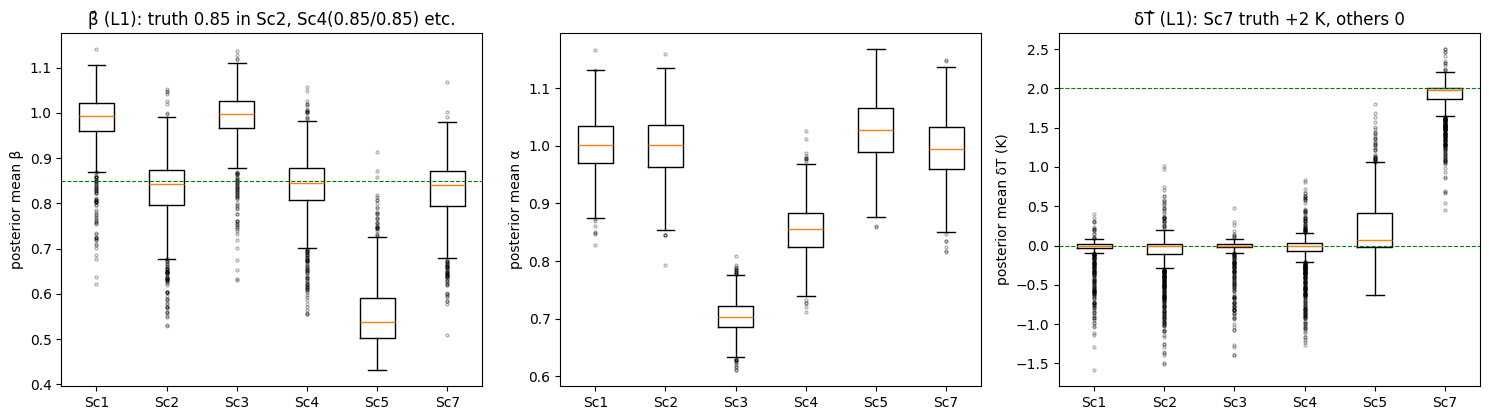

notebook wall time 11.9 min


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a_, (k, nm) in zip(ax, ((1, "β"), (0, "α"), (2, "δT (K)"))):
    data = [eL["s"][eL["sid"] == sc][:, :, k].mean(1) for sc in SCN]
    a_.boxplot(data, tick_labels=list(SCN.values()), flierprops=dict(ms=2, alpha=.3)); a_.set_ylabel(f"posterior mean {nm}")
    if k == 1: a_.axhline(0.85, color="g", ls="--", lw=.8); a_.set_title("β̂ (L1): truth 0.85 in Sc2, Sc4(0.85/0.85) etc.")
    if k == 2: a_.axhline(2.0, color="g", ls="--", lw=.8); a_.axhline(0, color="g", ls="--", lw=.8); a_.set_title("δT̂ (L1): Sc7 truth +2 K, others 0")
fig.tight_layout(); fig.savefig(FIGS / "09_N3_drift_aware.png", dpi=150); plt.show()
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


## 8. Interpretation

**Pre-set verdict: FIXED** — all four criteria of the decision rule are met, with one margin that is zero (below).

| criterion | result |
|---|---|
| (i) SBC, interior (n = 730): KS p ≥ 0.01 for α, β, δT; TARP p ≥ 0.01 | ensemble 0.061 / 0.135 / 0.122; TARP 0.017 — **pass, TARP only just** |
| (ii) Sc7 β coverage ≥ 0.80, \|bias\| ≤ 0.05 | **0.900, −0.024** (2-D production: 0.002, −0.395) |
| (iii) Sc7 δT coverage ≥ 0.80, \|bias\| ≤ 0.30 K | **0.920, −0.12 K** (posterior sd 0.20 K) |
| (iv) Sc1–Sc5 β coverage ≥ 0.80 each; macro-F1 ≥ 0.877 | coverage 0.89–0.95; **macro-F1 0.8771 — a margin of 0.0001** |

**What the remedy does.** Making the offset a parameter removes the Sc7 silent failure: β̂ bias −0.395 → −0.024, β coverage 0.002 → 0.900, class accuracy 0.341 → 0.820 (the class is now right for the right reason, β̂ ≈ 0.83), and the posterior recovers the offset (δT̂ = +1.88 K on average for a true +2 K, 90% coverage 0.92; D1: 0.90). The sensitivity
table shows the correction holds across offset sizes at (α, β) = (0.85, 0.85): β bias −0.01 to −0.03 and β coverage 0.90–0.94 at δT = 0, 0.25, 0.5, 1 and 2 K; δT̂ tracks the truth (0.17, 0.40, 0.91, 1.90 K) with a posterior sd of about 0.2 K, so a single window cannot resolve an offset below ≈ 0.4 K but also does not need to for β to be right.

**What it costs (the price is real).** The β posterior is wider in every well-specified scenario: sd 0.054–0.084 against 0.044 (×1.2 to ×1.9; Sc5, the saturated scenario, is the widest at 0.084, Sc2 and Sc4 0.071), because part of the temperature information is now spent on δT; α is almost unchanged (0.031–0.063 against 0.029–0.059).
Coverage is kept (0.89–0.95) and the calibrated width is the point: the posterior is honest about the loss. Class accuracy falls in Sc1 (0.970 → 0.915), Sc3 (0.992 → 0.934) and Sc2 (0.857 → 0.813), is unchanged in Sc4 (0.766 → 0.777) and Sc5 (0.977 → 0.986); macro-F1 over Sc1–Sc5 falls from 0.907 to **0.877**,
a loss of 0.030. Sc5 acquires a β bias of +0.055 and a δT bias of +0.22 K: with the valve saturated the temperature is no longer held at the setpoint and an offset on the sensor is partly confounded with β; observed, not investigated.

**Reading the verdict honestly.** The rule was fixed before the run and says FIXED. Two of its margins are thin and should be stated wherever the verdict is used: (a) the macro-F1 criterion is met by 0.0001 where its standard error with 5,000 windows is about 0.006, so the data cannot distinguish "within the price we set" from "slightly beyond it" — the honest statement
is "a price of about 0.03 in macro-F1"; (b) the TARP p-value of the ensemble is 0.017, and as in the production posterior the **single seeds do not all pass** (δT KS p 0.000 for seed 2 and 0.002 for seed 4; β 0.002–0.003 for seeds 0 and 2), so the ensemble is required here too. Prior leakage is 0.5% on average (max 0.34 for an individual window).

**Relation to the z_T guard (notebook 11b).** The two are complements, not alternatives. z_T (the mean temperature residual against T_sp) detects an offset down to ≈ 0.2 K in unsaturated windows (|z_T| > 10 in 82% of the 0.25 K windows and 100% from 0.5 K, 0% at 0 K in this sample) but does not correct anything; the drift-aware posterior corrects β and carries the right width, but only resolves offsets
above ≈ 0.4 K per window. A deployment would use z_T as the alarm and the drift-aware posterior as the estimate under an alarm, with the price above.

**Scope.** The remedy covers an additive constant offset of the temperature sensor within ±3 K (the prior), the only drift tested beyond the extension at (0.85, 0.85); a drift of the other sensors, a gain error, a time-varying drift or an offset outside the prior are not modelled, and the 2-D production posterior stays the model of record for well-specified plants.

**Ledger.** Supports: Sc7 can be remedied with a calibrated 3-parameter posterior (β coverage 0.90, bias −0.024) at a macro-F1 price of 0.03 and a β sd price of ×1.2–1.9. Documents: the price and the thin margins of the pre-set criteria; the Sc5 confounding. Does not support: robustness to sensor faults in general.
**For the main text (the user's decision):** the pre-set rule says Sc7 goes in with the remedy; the margins above are the caveats.